In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import (
    norm,
    lognorm,
    gamma,
    weibull_min,
    t
)

from scipy.stats import skew, kurtosis

sns.set_theme()

np.random.seed(42)

In [2]:
N = 100

# ==================================================
# SECRET DISTRIBUTION
# ==================================================

TRUE_DISTRIBUTION = "gamma"

if TRUE_DISTRIBUTION == "normal":
    data = np.random.normal(loc=100, scale=15, size=N)

elif TRUE_DISTRIBUTION == "lognormal":
    data = np.random.lognormal(mean=4.5, sigma=0.25, size=N)

elif TRUE_DISTRIBUTION == "gamma":
    data = np.random.gamma(shape=5, scale=20, size=N)

elif TRUE_DISTRIBUTION == "weibull":
    data = np.random.weibull(a=2.0, size=N) * 100

elif TRUE_DISTRIBUTION == "student_t":
    data = np.random.standard_t(df=4, size=N) * 15 + 100

else:
    raise ValueError("Unknown distribution")

In [3]:
mean_val = np.mean(data)
median_val = np.median(data)
sd_val = np.std(data, ddof=1)
skew_val = skew(data)
kurt_val = kurtosis(data)

print(f"Mean             : {mean_val:.2f}")
print(f"Median           : {median_val:.2f}")
print(f"Std              : {sd_val:.2f}")
print(f"Skewness         : {skew_val:.2f}")
print(f"Excess Kurtosis  : {kurt_val:.2f}")



"""
Rules of thumb:

Skewness
---------
0      = perfectly symmetric

|skew| < 0.5
    roughly symmetric

0.5 - 1
    moderate skew

> 1
    strong skew

Positive skew:
    long right tail

Negative skew:
    long left tail


Excess Kurtosis
----------------
0
    normal-like tails

> 0
    heavier tails
    more outliers

< 0
    lighter tails
    fewer outliers

> 1
    noticeably heavy-tailed

> 3
    very heavy-tailed
"""


print("\nInterpretation:")

# -------------------------------------------------
# SKEWNESS
# -------------------------------------------------

if abs(skew_val) < 0.5:
    print("- Skewness is small (approximately symmetric).")

elif abs(skew_val) < 1:
    print("- Moderate skewness detected.")

else:
    print("- Strong skewness detected.")

if skew_val > 0:
    print("  -> Right tail is longer than left tail.")

elif skew_val < 0:
    print("  -> Left tail is longer than right tail.")

# -------------------------------------------------
# KURTOSIS
# -------------------------------------------------

if abs(kurt_val) < 1:
    print("- Kurtosis near normal.")

elif kurt_val > 1:
    print("- Heavy tails / more extreme values than normal.")

else:
    print("- Light tails / fewer extreme values than normal.")

# -------------------------------------------------
# MEAN VS MEDIAN
# -------------------------------------------------

if mean_val > median_val:
    print("- Mean > Median (possible right skew).")

elif mean_val < median_val:
    print("- Mean < Median (possible left skew).")

else:
    print("- Mean and median are similar.")

Mean             : 98.57
Median           : 94.36
Std              : 38.36
Skewness         : 0.93
Excess Kurtosis  : 1.37

Interpretation:
- Moderate skewness detected.
  -> Right tail is longer than left tail.
- Heavy tails / more extreme values than normal.
- Mean > Median (possible right skew).


In [4]:
print("\nPossible clues:")

if np.min(data) >= 0:
    print("- Data are non-negative.")

if skew_val > 1:
    print("- Strong right skew suggests Gamma, Lognormal or Weibull.")

if abs(skew_val) < 0.5:
    print("- Symmetry suggests Normal or Student-t.")

if kurt_val > 2:
    print("- Heavy tails suggest Student-t or Lognormal.")

if kurt_val < 0:
    print("- Lighter tails than Normal.")


Possible clues:
- Data are non-negative.


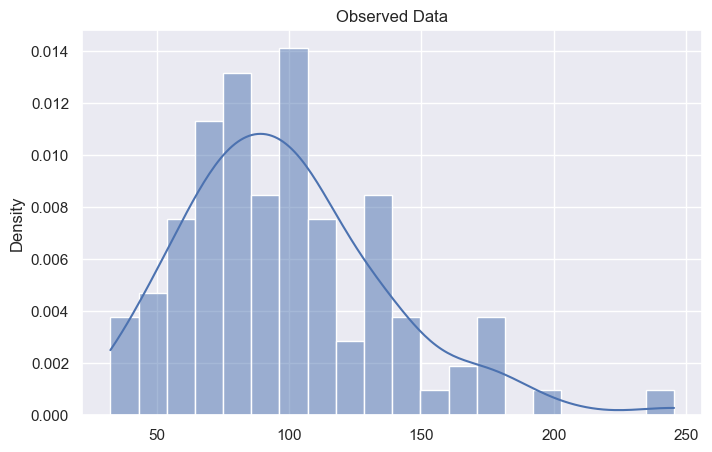

In [5]:
plt.figure(figsize=(8,5))

sns.histplot(
    data,
    bins=20,
    stat="density",
    kde=True
)

plt.title("Observed Data")
plt.show()

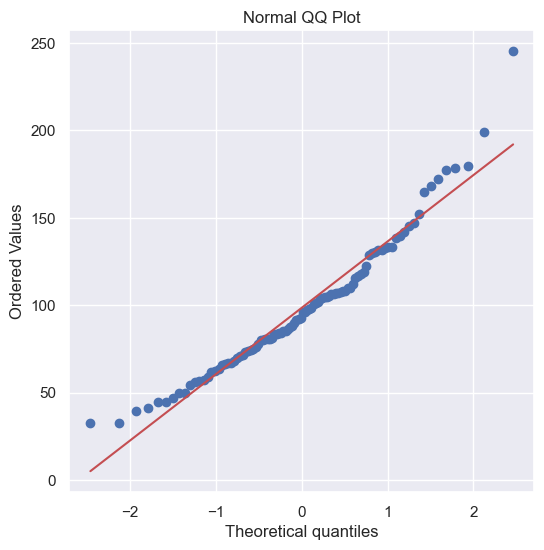

In [6]:
plt.figure(figsize=(6,6))

stats.probplot(data, dist="norm", plot=plt)

plt.title("Normal QQ Plot")
plt.show()

In [7]:
candidate_distributions = {
    "Normal": norm,
    "Lognormal": lognorm,
    "Gamma": gamma,
    "Weibull": weibull_min,
    "StudentT": t
}

fits = {}

for name, dist in candidate_distributions.items():

    params = dist.fit(data)

    loglik = np.sum(dist.logpdf(data, *params))

    k = len(params)

    aic = 2*k - 2*loglik

    fits[name] = {
        "params": params,
        "loglik": loglik,
        "aic": aic
    }

In [8]:
results = pd.DataFrame({
    name: {
        "AIC": fit["aic"],
        "LogLik": fit["loglik"]
    }
    for name, fit in fits.items()
}).T

results.sort_values("AIC")

,AIC,LogLik
Gamma,1004.790779,-499.395390
Lognormal,1004.894353,-499.447176
Normal,1016.162965,-506.081483
StudentT,1016.734856,-505.367428
Weibull,inf,-inf


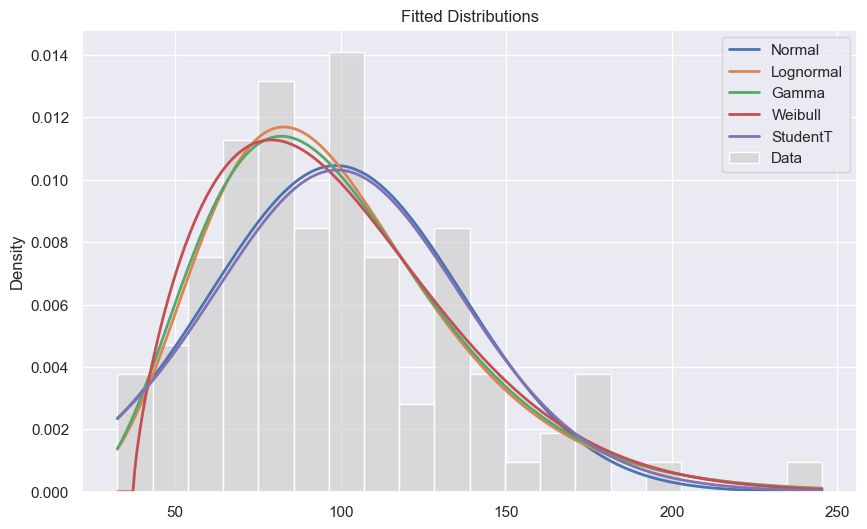

In [9]:
x = np.linspace(
    np.min(data),
    np.max(data),
    500
)

plt.figure(figsize=(10,6))

sns.histplot(
    data,
    bins=20,
    stat="density",
    color="lightgray",
    label="Data"
)

for name, dist in candidate_distributions.items():

    params = fits[name]["params"]

    y = dist.pdf(x, *params)

    plt.plot(
        x,
        y,
        linewidth=2,
        label=name
    )

plt.legend()
plt.title("Fitted Distributions")
plt.show()

In [10]:
ranking = (
    results
    .sort_values("AIC")
)
best_model = ranking.index[0]

print("Best model according to AIC:")
print(best_model)

Best model according to AIC:
Gamma


In [11]:
print("TRUE DISTRIBUTION:")
print(TRUE_DISTRIBUTION)

TRUE DISTRIBUTION:
gamma
